In [ ]:
#!pip install yfinance --upgrade

In [ ]:
import yfinance as yf
import pandas as pd
import datetime ,random
import numpy as np
import math
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense , Dropout , BatchNormalization , Input , Flatten , InputLayer
from tensorflow.keras.callbacks import EarlyStopping
from sklearn import preprocessing
import yfinance as yf
import scipy
import matplotlib.pyplot as plt
import copy


class SP500Predictor:

    def __init__(self, start_date, end_date , train_test_split):
        self.start_date = start_date
        self.end_date = end_date
        self.tickers = None

        self.data_unprocessed = None

        self.matrix_data = None
        self.matrix_data_return = None
        self.ticker_name_in_matrix_column = []


        self.train_test_split = train_test_split

        self.data_train = None
        self.data_test = None

        self.model_list = []

        self.modelVSrandomVSindex_return = []  # main_list
        self.daily_model_return_list = [] # daily_each_return
        self.tickers_index_selected_by_model_list = [] # ticker_num_list_total



    def get_tickers(self):
        data = pd.read_html('https://en.wikipedia.org/wiki/List_of_S%26P_500_companies')
        tickers = list(data[0]['Symbol'])
        tickers.append('^GSPC')
        return tickers[::-1]

    def get_data(self):

        if not(self.tickers) :
            self.tickers = self.get_tickers()

        data = []
        for symbol in self.tickers:
            try:
                df = yf.download(symbol, self.start_date, self.end_date)
                df = df.dropna()
                data.append(df)
                print(self.tickers.index(symbol) , ' : ' , symbol)
            except:
                print('can not get data : ' ,symbol)

        self.data_unprocessed = data
        return data


    def preprocess_data(self):

        date_list = []
        for i in range(len(self.data_unprocessed)):
            if len(self.data_unprocessed[i]) > len(date_list) :
                date_list = list(self.data_unprocessed[i].index)

        matrix_data = []
        for i in range(len(self.data_unprocessed)):
            if (len(self.data_unprocessed[i]) == len(date_list)) and (all((self.data_unprocessed[i].index) == date_list)):
                matrix_data.append(np.array(self.data_unprocessed[i]['Adj Close']))
                self.ticker_name_in_matrix_column.append(self.tickers[i])


        self.matrix_data = (np.array(matrix_data)).transpose()
        self.matrix_data_return = (self.matrix_data[1: , :] - self.matrix_data[:-1 , :]) / self.matrix_data[:-1 , :]



        len_data = len(self.matrix_data_return)

        self.data_train = self.matrix_data_return[ :int(len_data * self.train_test_split) , : ]
        self.data_test = self.matrix_data_return[ int(len_data * self.train_test_split): , : ]

        return self.data_train , self.data_test


    def plot_matrix_data(self):
        plt.figure(figsize=(28,13))
        plt.plot(self.matrix_data)
        plt.show()

    def plot_matrix_data_return(self):
        plt.figure(figsize=(28,13))
        plt.plot(self.matrix_data_return)
        plt.show()



    def train_model(self, model_count = 1 , save_model_in_list = False , encoder_1_neurons = 30 , encoder_2_neurons = 10 , hidden_neurons = 4 ,
                    decoder_1_neurons = 10 , decoder_2_neurons = 30 , batch_size_n = 32 , epochs_n=100):

        for number in range(model_count) :

            autoencoder = Sequential()
            autoencoder.add(Dense(encoder_1_neurons, activation = "tanh", input_shape=(self.data_train.shape[1], ) ))
            autoencoder.add(Dense(encoder_2_neurons, activation = "tanh"))
            autoencoder.add(Dense(hidden_neurons, activation = "tanh" , name = 'code'))
            autoencoder.add(Dense(decoder_1_neurons, activation = "tanh"))
            autoencoder.add(Dense(decoder_2_neurons, activation = "tanh"))
            autoencoder.add(Dense(self.data_train.shape[1], activation = "linear"))
         #   encoder = Model(inputs=autoencoder.input, outputs=autoencoder.get_layer('code').output)
            autoencoder.compile(optimizer='adam' , loss='mse')
            autoencoder.fit(x=self.data_train[:-1 , :] , y=self.data_train[1: , :] , batch_size = batch_size_n , epochs=epochs_n)

            if save_model_in_list:
                self.model_list.append(autoencoder)

            self._predict_current_model(autoencoder)


    def _predict_current_model(self, model):
        x_test = self.data_test
        prediction = np.array(model.predict(x_test[:-1]))

        r_random = []
        r_mean = []
        r_model = []
        ticker_num_list = []

        for i in range (len(prediction)) :
            r_model.append((x_test[1: , :])[i][list(prediction[i]).index(max(prediction[i]))])
            r_random.append((x_test[1: , :])[i][random.randint(0 , self.matrix_data.shape[1] - 1)])
            r_mean.append(np.mean((x_test[1: , :])[i]))

            ticker_num_list.append(list(prediction[i]).index(max(prediction[i])))

        self.tickers_index_selected_by_model_list.append(ticker_num_list)


        k_random = 1
        k_mean = 1
        k_model = 1

        for i in range(len(r_mean)) :
            k_mean = k_mean * (1+r_mean[i])

        for i in range(len(r_model)) :
            k_model = k_model * (1+r_model[i])

        for i in range(len(r_random)) :
            k_random = k_random * (1+r_random[i])

        self.modelVSrandomVSindex_return.append([k_model , k_random , k_mean])

        self.daily_model_return_list.append(r_model)


    def predict(self, model = None , x_test = None):

        if not(model):
            model = self.model_list[-1]

        if not(x_test):
            x_test = self.data_test

        prediction = np.array(model.predict(x_test[:-1]))
        r_model = []
        for i in range (len(prediction)) :
            r_model.append((x_test[1: , :])[i][list(prediction[i]).index(max(prediction[i]))])
        k_model = 1
        for i in range(len(r_model)) :
            k_model = k_model * (1+r_model[i])
        return k_model , r_model


    def predictors_output_report(self):

        main_list_np = np.array(self.modelVSrandomVSindex_return)

        print('average return of all predictors strategy : ' , np.mean(main_list_np[: , 0]))
        print('maximum return of all predictors strategy : ' , np.max(main_list_np[: , 0]))
        print('minimum return of all predictors strategy : ' , np.min(main_list_np[: , 0]))
        print('std of returns of all predictors strategy : ' , np.std(main_list_np[: , 0]))
        print('average 5% best return of predictors strategy  : ' , np.mean(np.array(sorted(list((main_list_np[: , 0])))[-int(main_list_np.shape[0]/20):])))
        print('average 5% worst return of predictors strategy : ' , np.mean(np.array(sorted(list((main_list_np[: , 0])))[:int(main_list_np.shape[0]/20)])))

        print('\n')

        print('average return of all random strategy : ' , np.mean(main_list_np[: , 1]))
        print('maximum return of all random strategy : ' , np.max(main_list_np[: , 1]))
        print('minumum return of all random strategy : ' , np.min(main_list_np[: , 1]))
        print('std of returns of all random strategy : ' , np.std(main_list_np[: , 1]))
        print('average 5% best return of random strategy  : ' , np.mean(np.array(sorted(list((main_list_np[: , 1])))[-int(main_list_np.shape[0]/20):])))
        print('average 5% worst return of random strategy : ' , np.mean(np.array(sorted(list((main_list_np[: , 1])))[:int(main_list_np.shape[0]/20)])))

        print('\n')

        print('average market return of all tickers : ' , np.mean(main_list_np[: , 2]))


    def plot_histogram_all_predictor_returns(self):

        # histogram of all random & model returns
        #1000 predictor : r1,r2, ... r1000
        #1000 random random : 1_ran1 , r_rand2 , .... , r_rand1000

        main_list_np = np.array(self.modelVSrandomVSindex_return)
        max_r = np.max(main_list_np)
        bins = np.linspace(0, max_r, 100)
        plt.figure(figsize=(28 , 14))
        plt.hist((main_list_np[: , 0] , main_list_np[: , 1]), bins , label=['predictor_returns','random_selection_returns'] )
        plt.legend(loc='upper right')
        plt.show()

    def plot_line_histogram_all_predictor_returns(self):

        main_list_np = np.array(self.modelVSrandomVSindex_return)
        max_r = np.max(main_list_np)
        bins = np.linspace(0, max_r, 100)
        plt.figure(figsize=(28 , 14))
        plt.hist((main_list_np[: , 0] , main_list_np[: , 1]), bins , label=['predictor_returns','random_selection_returns'] , histtype=u'step')
        plt.legend(loc='upper right')
        plt.show()


    def plot_all_predictors_strategy(self):

        daily_each_return = np.array(self.daily_model_return_list)

        for i in range(daily_each_return.shape[0]):
            for j in range(daily_each_return.shape[1]):
                if j == 0 :
                    daily_each_return[i][j] = 1+daily_each_return[i][j]
                else :
                    daily_each_return[i][j] = (daily_each_return[i][j] + 1 ) * daily_each_return[i][j-1]
        daily_each_return = daily_each_return.transpose()

        plt.figure(figsize=(28,13))
        plt.plot(daily_each_return)
        plt.show()


    def plot_all_predictors_min_max_avg_strategy(self):

        daily_each_return = np.array(self.daily_model_return_list)

        for i in range(daily_each_return.shape[0]):
            for j in range(daily_each_return.shape[1]):
                if j == 0 :
                    daily_each_return[i][j] = 1+daily_each_return[i][j]
                else :
                    daily_each_return[i][j] = (daily_each_return[i][j] + 1 ) * daily_each_return[i][j-1]
        daily_each_return = daily_each_return.transpose()

        # return of best(green) & worst(red) & avg(blue) and all other return
        max_index_r = list(daily_each_return[ -1 , :]).index(max(list(daily_each_return[ -1 , :])))
        min_index_r = list(daily_each_return[ -1 , :]).index(min(list(daily_each_return[ -1 , :])))
        plt.figure(figsize=(28,13))
        plt.plot(daily_each_return , alpha=0.1)
        plt.plot(daily_each_return.mean(axis=1) , 'b')
        plt.plot(daily_each_return[: , max_index_r] , 'g')
        plt.plot(daily_each_return[: , min_index_r] , 'r')
        plt.show()


    def plot_all_predictors_avg_strategy(self):

        daily_each_return = np.array(self.daily_model_return_list)

        for i in range(daily_each_return.shape[0]):
            for j in range(daily_each_return.shape[1]):
                if j == 0 :
                    daily_each_return[i][j] = 1+daily_each_return[i][j]
                else :
                    daily_each_return[i][j] = (daily_each_return[i][j] + 1 ) * daily_each_return[i][j-1]
        daily_each_return = daily_each_return.transpose()

        plt.figure(figsize=(28,13))
        plt.plot(daily_each_return.mean(axis=1))
        plt.show()


    def plot_all_predictors_best_worst_strategy(self):

        daily_each_return = np.array(self.daily_model_return_list)

        for i in range(daily_each_return.shape[0]):
            for j in range(daily_each_return.shape[1]):
                if j == 0 :
                    daily_each_return[i][j] = 1+daily_each_return[i][j]
                else :
                    daily_each_return[i][j] = (daily_each_return[i][j] + 1 ) * daily_each_return[i][j-1]
        daily_each_return = daily_each_return.transpose()

        best_returns = []
        worst_returns = []

        best_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.95)]
        worst_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.05)]

        for i in range(daily_each_return.shape[1]):
            if daily_each_return[: , i][-1] <= worst_limit :
                worst_returns.append(daily_each_return[: , i])
            if daily_each_return[: , i][-1] >= best_limit :
                best_returns.append(daily_each_return[: , i])

        best_returns , worst_returns = np.array(best_returns).transpose() , np.array(worst_returns).transpose()
        plt.figure(figsize=(28,13))
        plt.plot(daily_each_return , alpha=0.1)
        plt.plot(best_returns , 'g')
        plt.plot(worst_returns , 'r')
        plt.show()

    def plot_all_predictors_bestAVG_worstAVG_strategy(self):

        daily_each_return = np.array(self.daily_model_return_list)

        for i in range(daily_each_return.shape[0]):
            for j in range(daily_each_return.shape[1]):
                if j == 0 :
                    daily_each_return[i][j] = 1+daily_each_return[i][j]
                else :
                    daily_each_return[i][j] = (daily_each_return[i][j] + 1 ) * daily_each_return[i][j-1]
        daily_each_return = daily_each_return.transpose()

        best_returns = []
        worst_returns = []

        best_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.95)]
        worst_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.05)]

        for i in range(daily_each_return.shape[1]):
            if daily_each_return[: , i][-1] <= worst_limit :
                worst_returns.append(daily_each_return[: , i])
            if daily_each_return[: , i][-1] >= best_limit :
                best_returns.append(daily_each_return[: , i])

        best_returns , worst_returns = np.array(best_returns).transpose() , np.array(worst_returns).transpose()
        plt.figure(figsize=(28,13))
        plt.plot(daily_each_return , alpha=0.1)
        plt.plot(daily_each_return.mean(axis=1) , 'b')
        plt.plot(best_returns.mean(axis = 1) , 'g')
        plt.plot(worst_returns.mean(axis=1) , 'r')
        plt.show()


##############################################################################################


    def plot_number_of_tickers_per_day_in_portfolio(self):

        ticker_number_list_total = np.array(self.tickers_index_selected_by_model_list)
        ticker_number_list_total = ticker_number_list_total.transpose()

        number_of_ticker_per_day_in_portfolio = []

        for i in ticker_number_list_total :
            number_of_ticker_per_day_in_portfolio.append(len(set(i)))

        plt.figure(figsize=(28,13))
        plt.plot(number_of_ticker_per_day_in_portfolio)
        plt.show()

    def plot_line_histogram_number_of_tickers_per_day_in_portfolio(self):

        ticker_number_list_total = np.array(self.tickers_index_selected_by_model_list)
        ticker_number_list_total = ticker_number_list_total.transpose()

        number_of_ticker_per_day_in_portfolio = []

        for i in ticker_number_list_total :
            number_of_ticker_per_day_in_portfolio.append(len(set(i)))

        max_r = np.max(number_of_ticker_per_day_in_portfolio)

        bins = np.linspace(0, max_r, 100)
        plt.figure(figsize=(28 , 14))
        plt.hist(number_of_ticker_per_day_in_portfolio , bins , label=['x'] , histtype=u'step')
        plt.legend(loc='upper right')
        plt.show()

    def plot_histogram_number_of_tickers_per_day_in_portfolio(self):

        ticker_number_list_total = np.array(self.tickers_index_selected_by_model_list)
        ticker_number_list_total = ticker_number_list_total.transpose()

        number_of_ticker_per_day_in_portfolio = []

        for i in ticker_number_list_total :
            number_of_ticker_per_day_in_portfolio.append(len(set(i)))

        max_r = np.max(number_of_ticker_per_day_in_portfolio)

        bins = np.linspace(0, max_r, 100)
        plt.figure(figsize=(28 , 14))
        plt.hist(number_of_ticker_per_day_in_portfolio , bins , label=['x'])
        plt.legend(loc='upper right')
        plt.show()

    def number_of_tickers_per_day_in_portfolio_report(self):

        ticker_number_list_total = np.array(self.tickers_index_selected_by_model_list)
        ticker_number_list_total = ticker_number_list_total.transpose()

        number_of_ticker_per_day_in_portfolio = []

        for i in ticker_number_list_total :
            number_of_ticker_per_day_in_portfolio.append(len(set(i)))

        print('min selected ticker per day : ' , min(number_of_ticker_per_day_in_portfolio))
        print('max selected ticker per day : ' , max(number_of_ticker_per_day_in_portfolio))
        print('average selected ticker per day : ' , np.mean(np.array(number_of_ticker_per_day_in_portfolio)))
        print('std selected ticker per day : ' , np.std(np.array(number_of_ticker_per_day_in_portfolio)))
        print('\n')

        l = len((sorted(number_of_ticker_per_day_in_portfolio)))

        for i in range(5 , 96 , 5) :
            print(i , '% of days contains less than' , sorted(number_of_ticker_per_day_in_portfolio)[int(i/100*l)] , 'tickers in portfolio')


    def predictors_sharp_ratio_report(self):

        sharpe_list = []

        for i in range(len(self.daily_model_return_list)) :
            sharpe_i = ((1 + np.mean(self.daily_model_return_list[i])) ** 252 - 0.0222) / (np.std(self.daily_model_return_list[i]) * (252**0.5))
            sharpe_list.append(sharpe_i)

        print('min sharpe ratio of all models : ' , min(sharpe_list))
        print('max sharpe ratio of all models : ' , max(sharpe_list))
        print('average sharpe ratio of all models : ' , np.mean(np.array(sharpe_list)))
        print('std sharpe ratio of all models : ' , np.std(np.array(sharpe_list)))
        print('\n')

        l = len((sorted(sharpe_list)))

        for i in range(5 , 96 , 5) :
            print(i , '% of models have sharpe ratio greater than' , sorted(sharpe_list , reverse=True)[int(i/100*l)] )


    def plot_histogram_sharpe_ratio_all_predictors(self):

        sharpe_list = []

        for i in range(len(self.daily_model_return_list)) :
            sharpe_i = ((1 + np.mean(self.daily_model_return_list[i])) ** 252 - 0.0222) / (np.std(self.daily_model_return_list[i]) * (252**0.5))
            sharpe_list.append(sharpe_i)

        max_r = np.max(sharpe_list)
        min_r = np.min(sharpe_list)
        bins = np.linspace(min_r, max_r, 100)
        plt.figure(figsize=(28 , 14))
        plt.hist(sharpe_list , bins , label=['sharpe ration of all models histogram'])
        plt.legend(loc='upper right')
        plt.show()



    def plot_line_histogram_sharpe_ratio_all_predictors(self):

        sharpe_list = []

        for i in range(len(self.daily_model_return_list)) :
            sharpe_i = ((1 + np.mean(self.daily_model_return_list[i])) ** 252 - 0.0222) / (np.std(self.daily_model_return_list[i]) * (252**0.5))
            sharpe_list.append(sharpe_i)

        max_r = np.max(sharpe_list)
        min_r = np.min(sharpe_list)
        bins = np.linspace(min_r, max_r, 100)
        plt.figure(figsize=(28 , 14))
        plt.hist(sharpe_list , bins , label=['sharpe ration of all models histogram'] , histtype=u'step')
        plt.legend(loc='upper right')
        plt.show()


    def plot_all_predictors_avg_strategy_vs_index(self):

        l = len(self.matrix_data)
        daily_model_return_list = np.array(self.daily_model_return_list)
        index_return = list(self.matrix_data[int(self.train_test_split*l): , 0] / self.matrix_data[int(self.train_test_split*l) , 0])
        model_return_per_day = list(daily_model_return_list.mean(axis=0))
        model_return = [1]

        for i in model_return_per_day:
            model_return.append(model_return[-1] * (1+i))

        plt.figure(figsize=(28,13))
        plt.plot(model_return , 'g')
        plt.plot(index_return , 'r')
        plt.show()

    def all_predictors_avg_strategy_vs_index_report(self):

        l = len(self.matrix_data)
        daily_model_return_list = np.array(self.daily_model_return_list)
        index_return = list(self.matrix_data[int(self.train_test_split*l): , 0] / self.matrix_data[int(self.train_test_split*l) , 0])
        model_return_per_day = list(daily_model_return_list.mean(axis=0))
        model_return = [1]
        for i in model_return_per_day:
            model_return.append(model_return[-1] * (1+i))


        year_count = int(len(model_return) / 252)

        for i in range(year_count):

            print( str(i+1) + 'th year model return : ' , (model_return[252 *(i+1)] - model_return[252*i])/model_return[252*i])
            print( str(i+1) + 'th year index return : ' , (index_return[252 *(i+1)] - index_return[252*i])/index_return[252*i])
            print('------------------------------------------------')


In [ ]:
my_SP500Predictor = SP500Predictor(start_date='2011-01-01', end_date='2023-01-15' , train_test_split=(7/12))

In [1]:
my_SP500Predictor.get_tickers()

NameError: name 'my_SP500Predictor' is not defined

In [ ]:
my_SP500Predictor.get_tickers()

HTTPError: HTTP Error 403: Forbidden

In [ ]:
my_SP500Predictor.get_data()

HTTPError: HTTP Error 403: Forbidden

In [ ]:
my_SP500Predictor.preprocess_data()

TypeError: object of type 'NoneType' has no len()

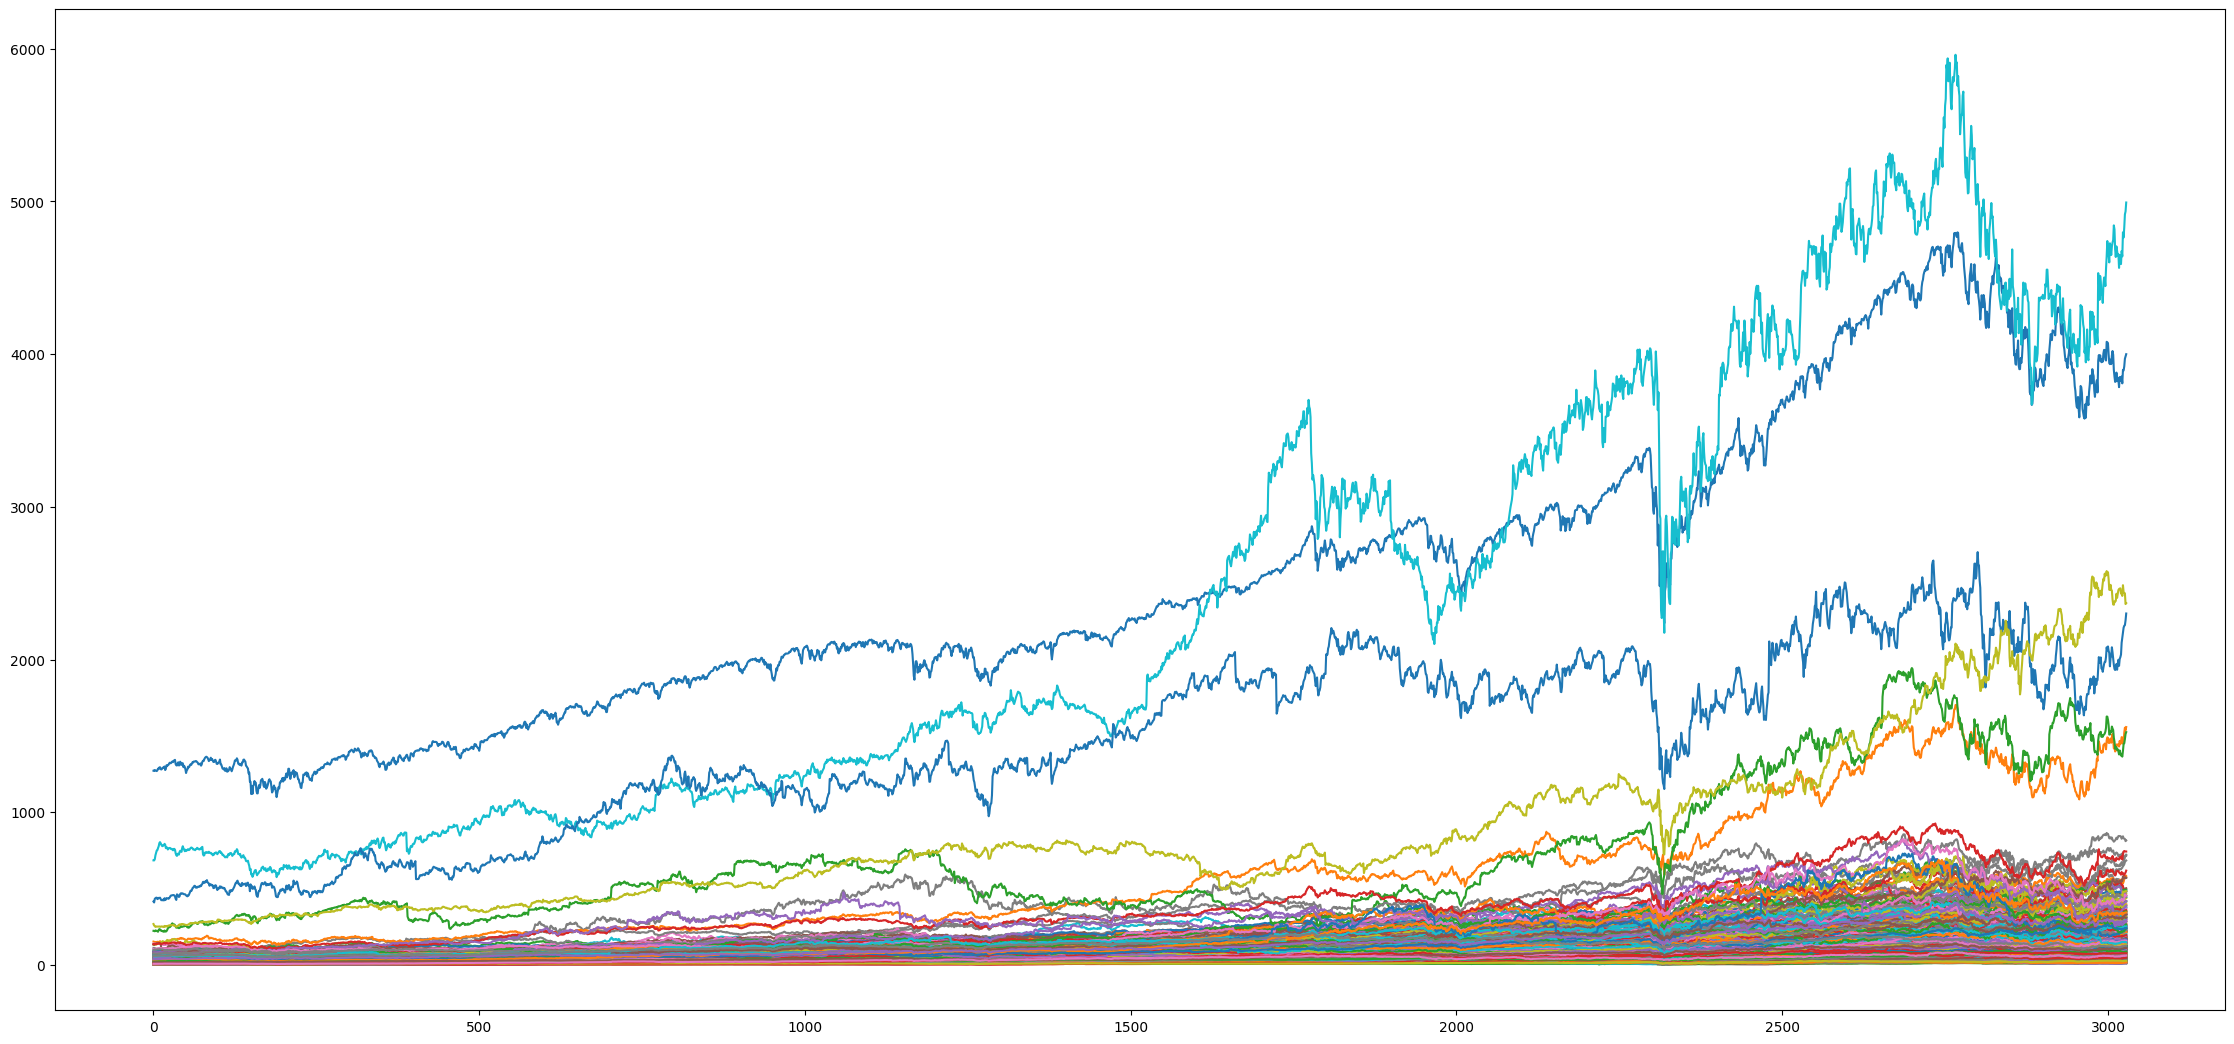

In [ ]:
my_SP500Predictor.plot_matrix_data()
(pd,DataFrame(matrix_data).to_csv)('matrix_data'+'.csv')

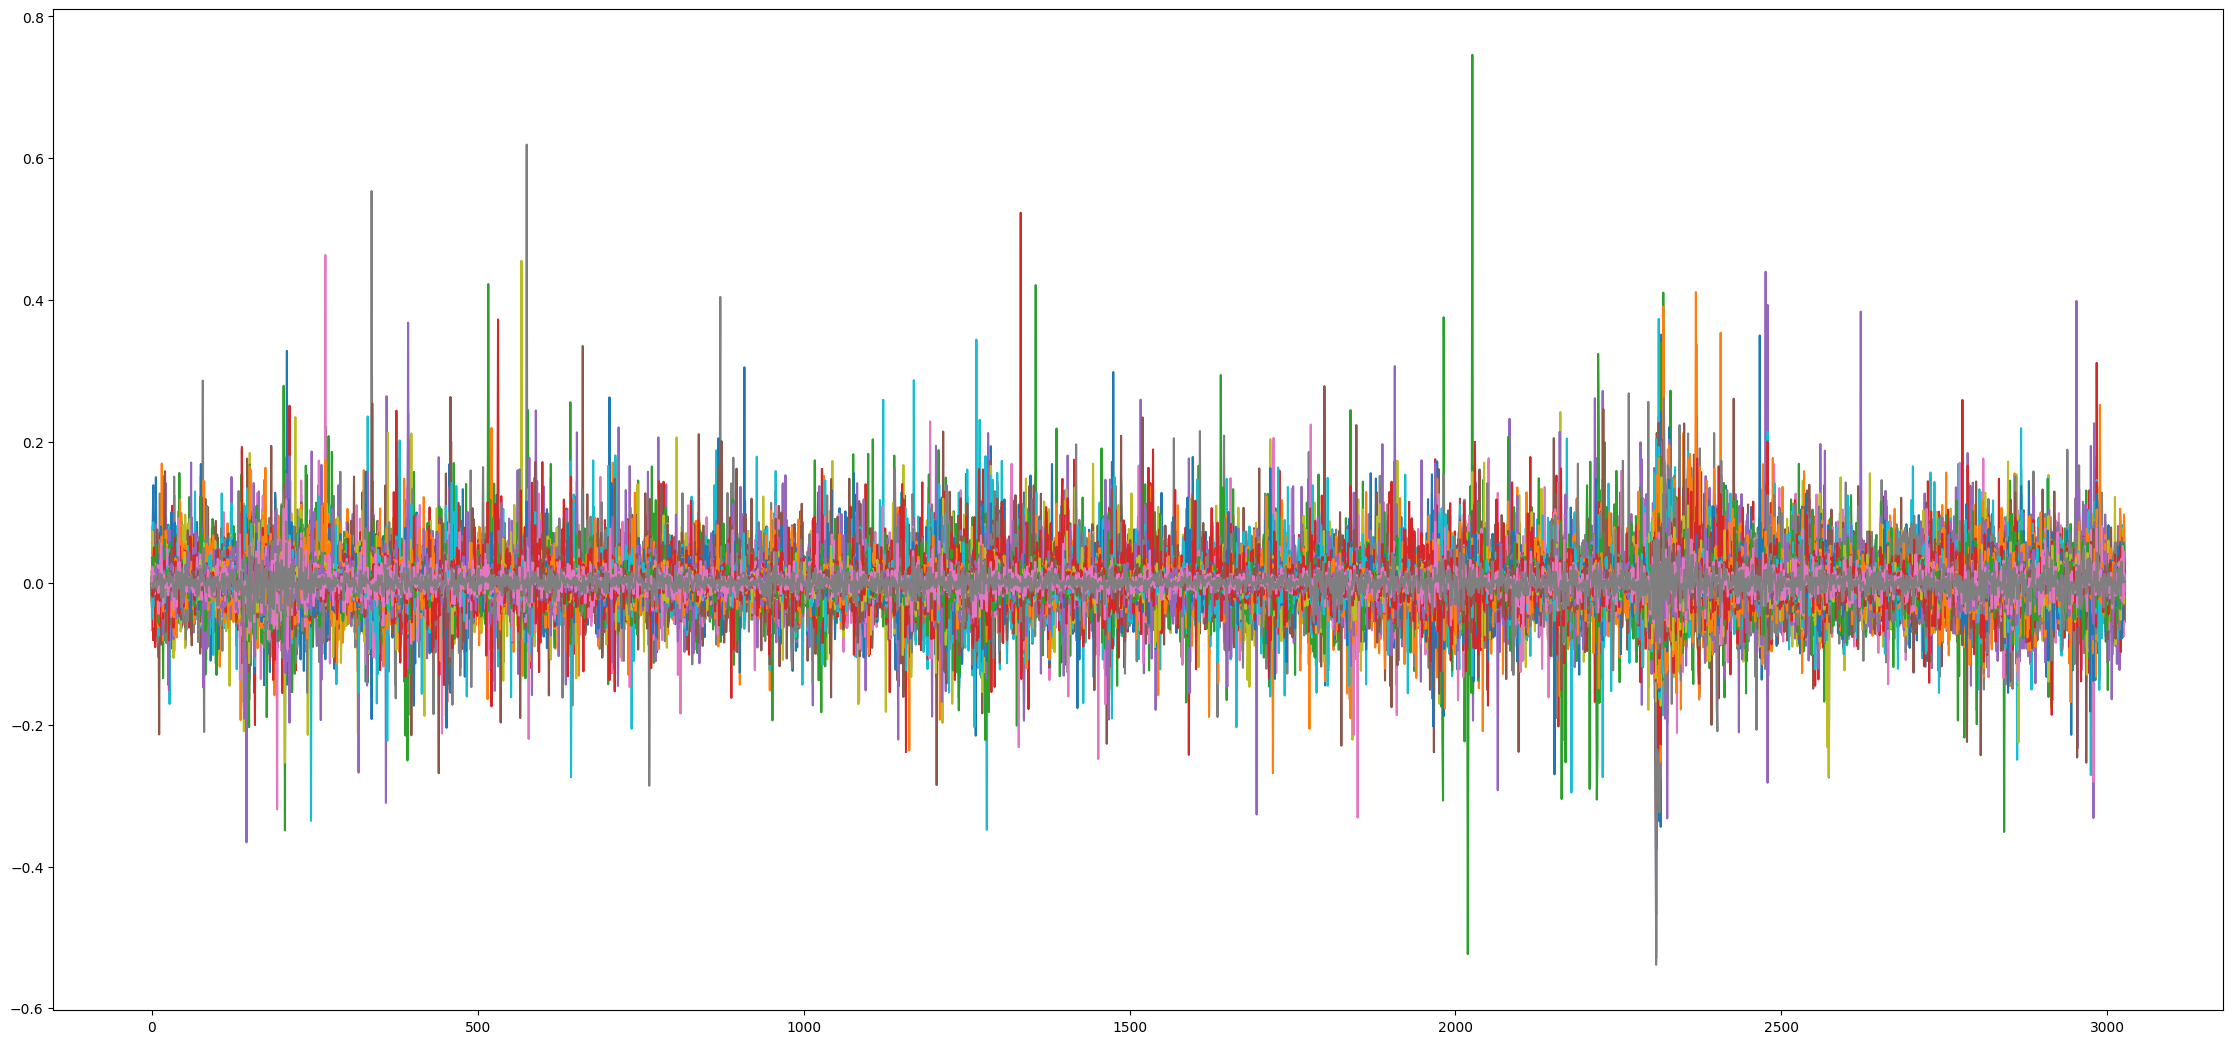

In [ ]:
my_SP500Predictor.plot_matrix_data_return()


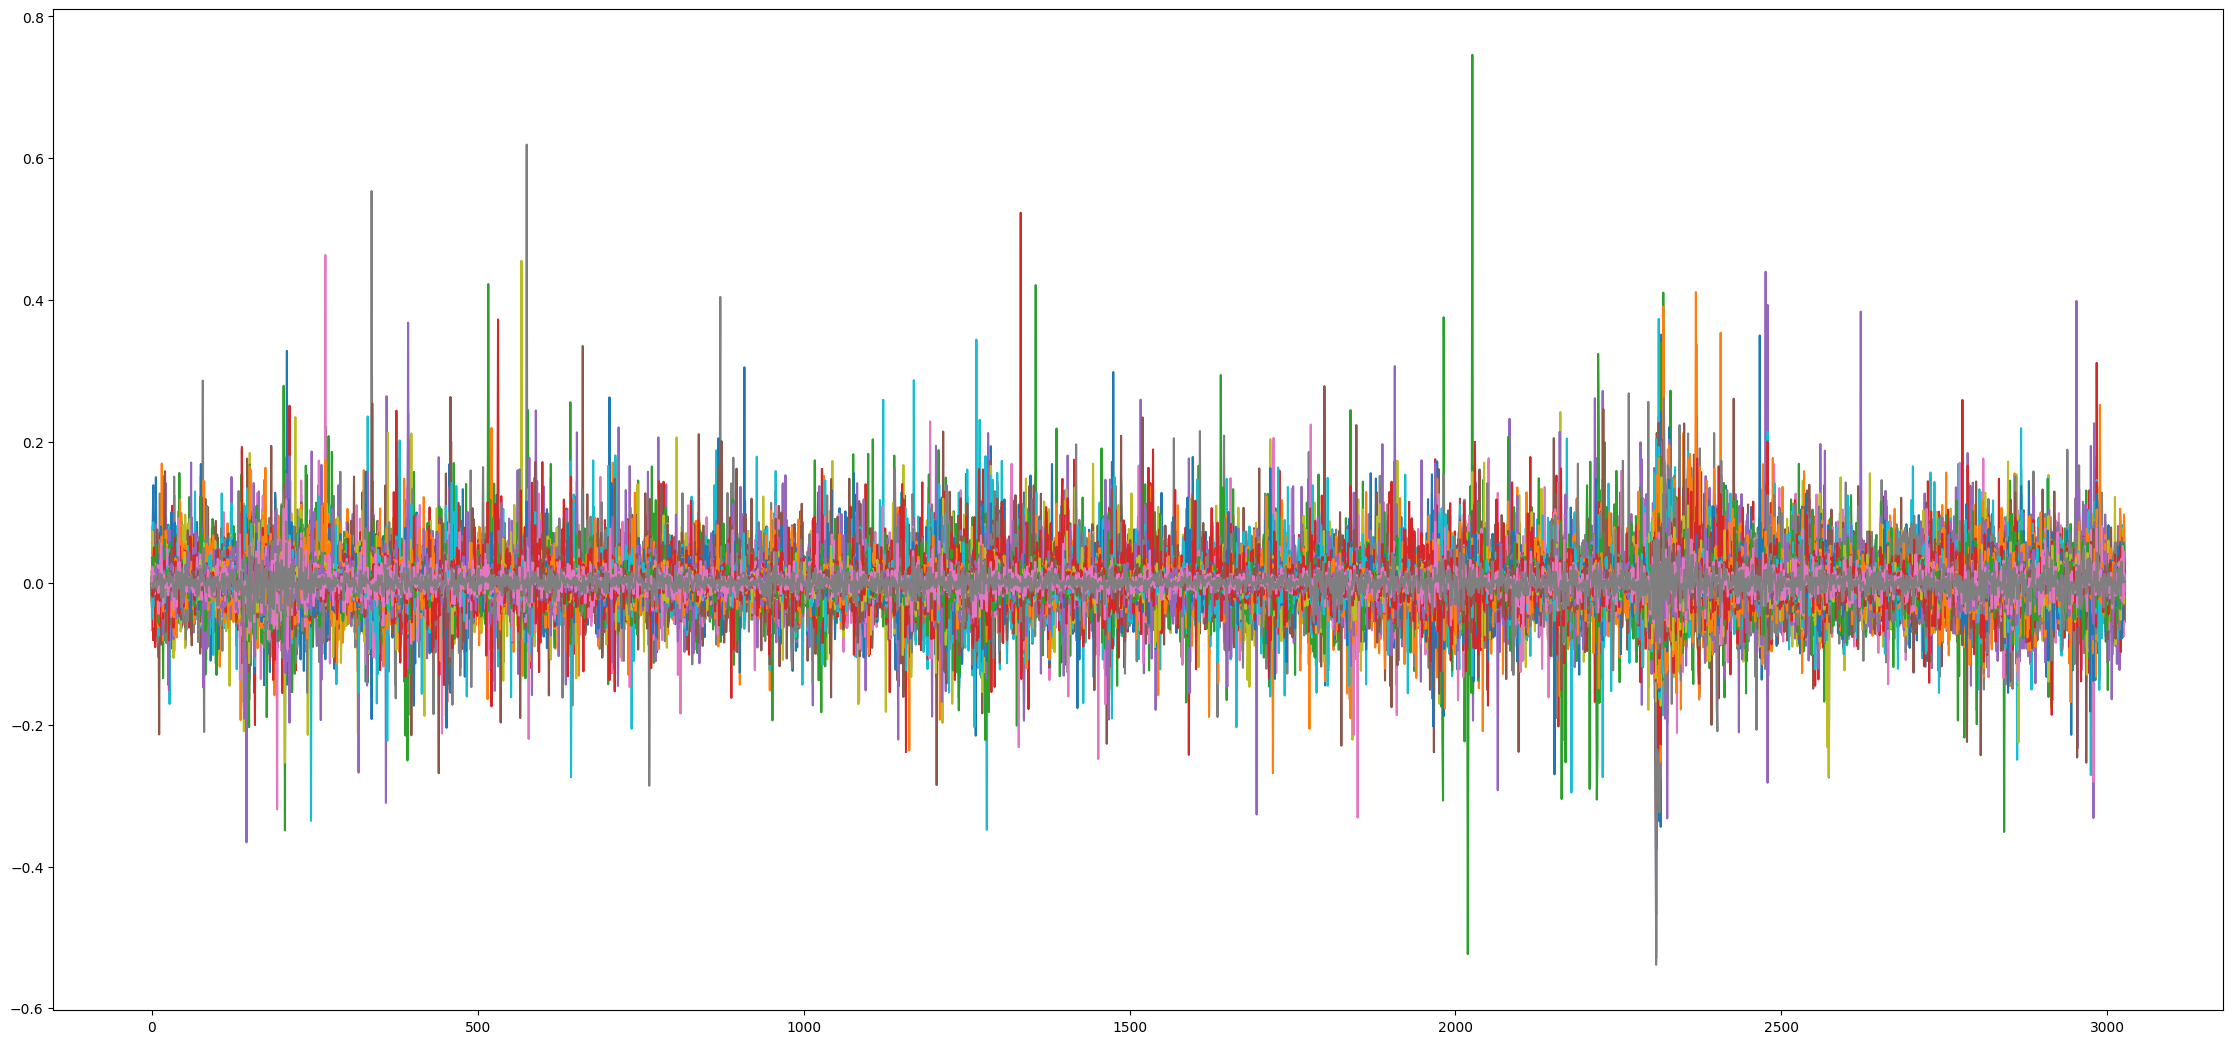

In [ ]:
my_SP500Predictor.plot_matrix_data_return()

In [ ]:
my_SP500Predictor.plot_predictors_output_report()

IndexError: ignored

In [ ]:
my_SP500Predictor.plot_histogram_all_predictor_returns()
(pd,DataFrame(my_SP500Predictor).to_csv)('my_SP500Predictor'+'.csv')

NameError: name 'my_SP500Predictor' is not defined

In [ ]:
my_SP500Predictor.plot_line_histogram_all_predictor_returns()

In [ ]:
my_SP500Predictor.plot_all_predictors_strategy()

In [ ]:
my_SP500Predictor.plot_all_predictors_min_max_avg_strategy()

In [ ]:
my_SP500Predictor.plot_all_predictors_avg_strategy()

In [ ]:
my_SP500Predictor.plot_all_predictors_best_worst_strategy()

In [ ]:
my_SP500Predictor.plot_all_predictors_bestAVG_worstAVG_strategy()

In [ ]:
my_SP500Predictor.plot_number_of_tickers_per_day_in_portfolio()

In [ ]:
my_SP500Predictor.plot_line_histogram_number_of_tickers_per_day_in_portfolio()

In [ ]:
my_SP500Predictor.plot_histogram_number_of_tickers_per_day_in_portfolio()

In [ ]:
my_SP500Predictor.number_of_tickers_per_day_in_portfolio_report()

In [ ]:
my_SP500Predictor.predictors_sharp_ratio_report()

In [ ]:
my_SP500Predictor.plot_histogram_sharpe_ratio_all_predictors()

In [ ]:
my_SP500Predictor.plot_line_histogram_sharpe_ratio_all_predictors()

In [ ]:
my_SP500Predictor.plot_all_predictors_avg_strategy_vs_index()

In [ ]:
my_SP500Predictor.all_predictors_avg_strategy_vs_index_report()